# Application of the Dynamic Battery Degradation Model

## Overview
This notebook demonstrates the application of the semi-empirical battery degradation models utilized in our manuscript, *"The potential and viability of V2G for California EV drivers"*.

## Objective
To demonstrate this application, the notebook loads an example vehicle usage data of a **Daily Charger**. It then utilizes the `calculate_capacity_loss` function to apply the dynamic battery model to this usage data, estimating the total capacity loss ($q_{\text{Loss}}$), as well as isolating the specific contributions from cycle aging ($q_{\text{Loss,Cyc}}$) and calendar aging ($q_{\text{Loss,Cal}}$).

## Libraries and Setup

In [1]:
%matplotlib inline
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Add repository root to system path to allow local imports
repo_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

# Explicitly import the degradation model
from src.battery_model import *

##  Load Usage Data

In [2]:
# Using the 'Daily Charger' vehicle usage profile as the demonstration
profile_name = 'daily_charger'
file_path = f'../data/synthetic_vehicle_usage/{profile_name}.parquet'

usage_df = pd.read_parquet(file_path)

# Extract time-series arrays for the simulation
time_seconds = usage_df['Time (s)'].values
c_rate_data = usage_df['C-rate'].values
soc_data = usage_df['SOC'].values

# Inspect the telemetry
usage_df.head()

,Time (s),C-rate,SOC,timestamp
0,0.0,0.0,0.75,2024-01-01 00:00:00
1,1.0,0.0,0.75,2024-01-01 00:00:01
2,25200.0,0.0,0.75,2024-01-01 07:00:00
3,25201.0,-0.0,0.75,2024-01-01 07:00:01
4,25202.0,-0.0,0.75,2024-01-01 07:00:02


## Apply Battery Model and Visualize Capacity Loss from 0 to 10 years

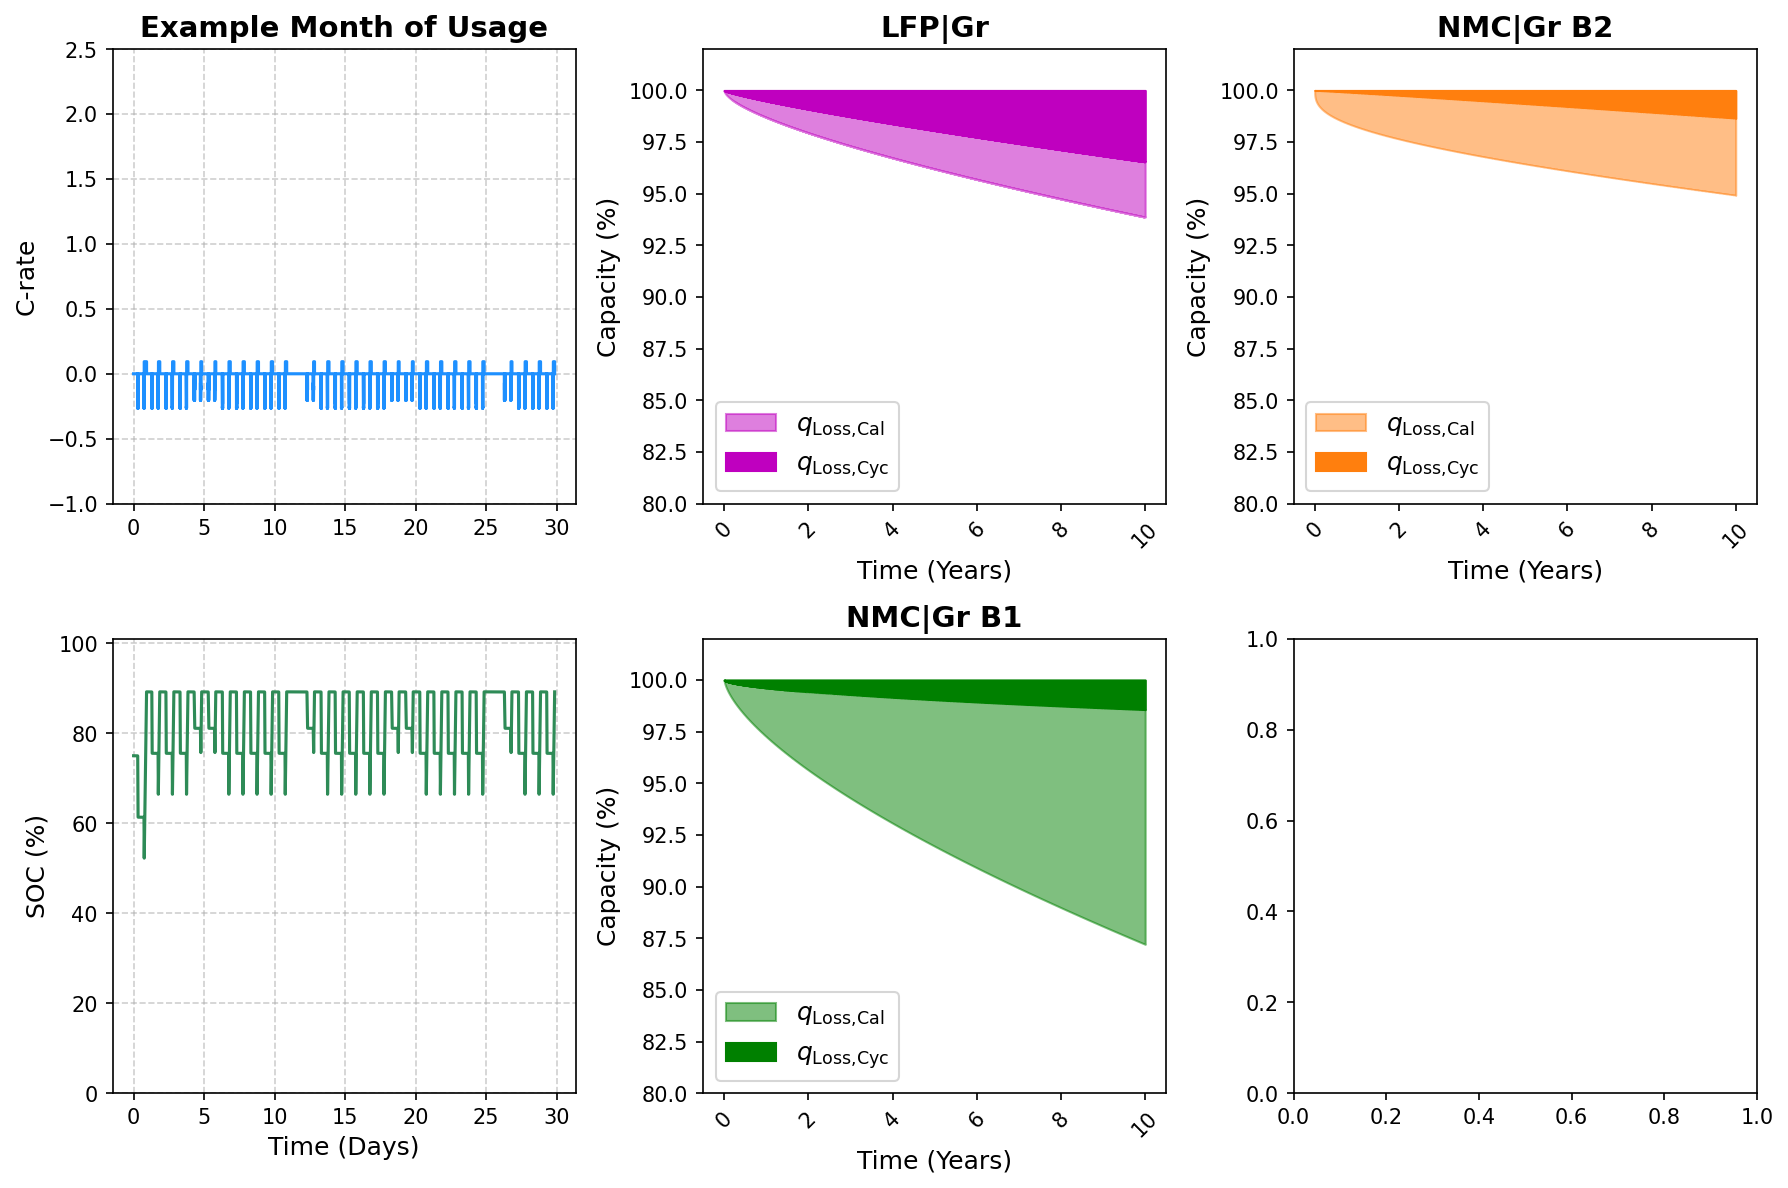

In [3]:
# Assume a constant average environmental temperature representative of California (14°C converted to Kelvin)
temp_avg_k = 14.0 + 273.15 

chemistries = ["LFP|Gr", "NMC|Gr B1", "NMC|Gr B2"]
colors = {"LFP|Gr": 'm', "NMC|Gr B1": 'g', "NMC|Gr B2": 'tab:orange'}

# Initialize a 2x3 plotting grid
fig, ax = plt.subplots(2, 3, figsize=(12, 8), dpi=150)

# ---------------------------------------------------------
# 1. Plot a 1-month snippet of usage on the left-most column
# ---------------------------------------------------------
time_days = time_seconds / (3600 * 24)
month_mask = time_days < 30

# First subplot: C-rate
ax[0, 0].plot(time_days[month_mask], c_rate_data[month_mask], color='dodgerblue')
ax[0, 0].set_title('Example Month of Usage', fontsize=14, fontweight='bold')
ax[0, 0].set_ylabel('C-rate', fontsize=12)
ax[0, 0].grid(True, linestyle='--', alpha=0.6)
ax[0, 0].set_ylim([-1, 2.5])

# Second subplot: SOC
ax[1, 0].plot(time_days[month_mask], soc_data[month_mask] * 100, color='seagreen')
ax[1, 0].set_ylabel('SOC (%)', fontsize=12)
ax[1, 0].set_xlabel('Time (Days)', fontsize=12)
ax[1, 0].set_ylim([0, 101])
ax[1, 0].grid(True, linestyle='--', alpha=0.6)

# ---------------------------------------------------------
# 2. Iterate through chemistries and plot capacity loss
# ---------------------------------------------------------
col_idx = 1
row_idx = 0

for chemistry in chemistries:
    
    # Calculate capacity and aging components
    capacity, capacity_cyc, capacity_cal = calculate_capacity_loss(
        soc_data, c_rate_data, time_seconds, chemistry, temp_avg_k
    )
    
    # Sub-sampling step for faster, cleaner plotting
    s = 100
    t_years = time_seconds[::s] / (3600 * 24 * 365)
    
    # Plot calendar aging fill
    ax[row_idx, col_idx].fill_between(
        t_years, 100, capacity[::s] * 100,
        color=colors[chemistry], alpha=0.5, label=r'$q_{\text{Loss,Cal}}$'
    )
    
    # Plot cycle aging fill
    ax[row_idx, col_idx].fill_between(
        t_years, 100, capacity_cyc[::s] * 100,
        color=colors[chemistry], alpha=1.0, label=r'$q_{\text{Loss,Cyc}}$'
    )
    
    # Formatting
    ax[row_idx, col_idx].set_ylabel('Capacity (%)', fontsize=12)
    ax[row_idx, col_idx].set_xlabel('Time (Years)', fontsize=12)
    ax[row_idx, col_idx].set_title(chemistry, fontsize=14, fontweight='bold')
    ax[row_idx, col_idx].set_ylim([80, 102])
    ax[row_idx, col_idx].legend(loc='lower left', fontsize=12)
    ax[row_idx, col_idx].tick_params(axis='x', rotation=45)
    
    # Update grid indices for the next chemistry
    row_idx += 1
    if row_idx > 1:
        row_idx = 0
        col_idx += 1
        
fig.tight_layout(pad=1.0)
plt.show()

## Apply Battery Model and Extract Capacity Loss at 10 years 

In [4]:
# Define exactly 10 years in seconds (using 365 days)
ten_years_seconds = 10 * 365 * 24 * 3600

# Initialize a single dictionary to store all results
summary_results = {}

for chemistry in chemistries:
    # Recalculate or retrieve the arrays for the given chemistry
    capacity, capacity_cyc, capacity_cal = calculate_capacity_loss(
        soc_data, c_rate_data, time_seconds, chemistry, temp_avg_k
    )
    
    # Use linear interpolation to find the exact value at 10 years
    loss_total_10yr = np.interp(ten_years_seconds, time_seconds, (1.0 - capacity) * 100)
    loss_cyc_10yr = np.interp(ten_years_seconds, time_seconds, (1-capacity_cyc) * 100)
    loss_cal_10yr = np.interp(ten_years_seconds, time_seconds, (1-capacity_cal) * 100)
    
    # Dynamically assign keys for each chemistry
    summary_results[f"q_loss_{chemistry}_10_years (%)"] = loss_total_10yr
    summary_results[f"q_loss_cyc_{chemistry}_10_years (%)"] = loss_cyc_10yr
    summary_results[f"q_loss_cal_{chemistry}_10_years (%)"] = loss_cal_10yr

# Convert to a Pandas DataFrame (passing index=[0] because it is a single row)
summary_df = pd.DataFrame(summary_results, index=[0])

# Display the dataframe
summary_df

,q_loss_LFP|Gr_10_years (%),q_loss_cyc_LFP|Gr_10_years (%),q_loss_cal_LFP|Gr_10_years (%),q_loss_NMC|Gr B1_10_years (%),q_loss_cyc_NMC|Gr B1_10_years (%),q_loss_cal_NMC|Gr B1_10_years (%),q_loss_NMC|Gr B2_10_years (%),q_loss_cyc_NMC|Gr B2_10_years (%),q_loss_cal_NMC|Gr B2_10_years (%)
0,6.130339,3.450011,2.680328,12.794683,1.435854,11.358829,5.077079,1.350793,3.726287
